# Analysis of power change fits

In [5]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [6]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"
PLOT_DIR_NEW.mkdir(exist_ok=True)

In [7]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_vehicle.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_empa.nc")
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["power_change_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["power_change_empa"])

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.316,0.258,-0.820,0.143,0.007,0.004,1400.0,2144.0,1.0
activity_type[single],-0.082,0.077,-0.232,0.062,0.001,0.001,3056.0,2466.0,1.0
gtyp[fa/fa],0.270,0.373,-0.480,0.936,0.010,0.008,1413.0,1768.0,1.0
age[Young],0.033,0.355,-0.681,0.684,0.009,0.008,1535.0,1964.0,1.0
sex[M],0.146,0.351,-0.536,0.780,0.009,0.007,1669.0,1980.0,1.0
"gtyp:age[fa/fa, Young]",-0.106,0.508,-1.038,0.874,0.013,0.010,1600.0,1928.0,1.0
"gtyp:sex[fa/fa, M]",-0.317,0.512,-1.295,0.632,0.013,0.010,1594.0,2027.0,1.0
1|rat_sigma,0.657,0.104,0.475,0.856,0.003,0.002,1054.0,1828.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-1.107,0.354,-1.778,-0.439,0.008,0.007,1749.0,2316.0,1.0
activity_type[single],0.219,0.094,0.041,0.391,0.001,0.002,4219.0,2501.0,1.0
gtyp[fa/fa],0.483,0.516,-0.449,1.480,0.012,0.009,1773.0,2059.0,1.0
age[Young],0.341,0.484,-0.560,1.250,0.011,0.010,2060.0,2176.0,1.0
sex[M],-1.012,0.485,-1.976,-0.160,0.011,0.010,1899.0,2059.0,1.0
"gtyp:age[fa/fa, Young]",-0.815,0.692,-2.056,0.563,0.016,0.013,1926.0,2368.0,1.0
"gtyp:sex[fa/fa, M]",0.868,0.711,-0.515,2.133,0.016,0.014,1943.0,2169.0,1.0
1|rat_sigma,0.911,0.146,0.649,1.184,0.004,0.003,1230.0,2183.0,1.0


## Posterior predictive checks

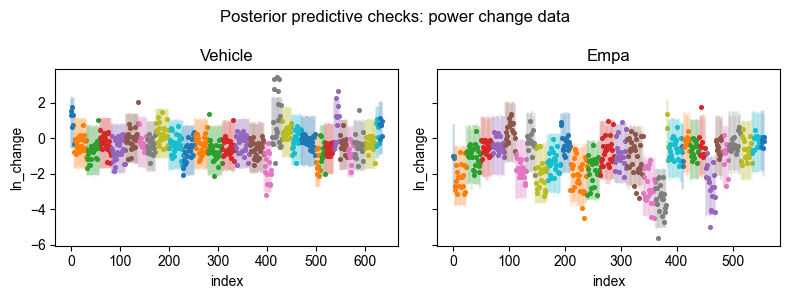

In [8]:
f, axes = plt.subplots(1, 2, figsize=[8, 3], sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="ln_change", groupcol="rat")
    ax.set_title(name.capitalize());
    ax.get_legend().remove()

f.suptitle("Posterior predictive checks: power change data");
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_power_change.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%-99% posterior predictive intervals.

## Effects

Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa - fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.

In [10]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="TS (ln injected/baseline)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups) | {
        # activity_type's reference level is double, so negate to get double - single
        "double - single": -idata.posterior["activity_type"].sel(activity_type_dim="single", drop=True),
    }
    for idata, t_groups in ((idata_vehicle, t_groups_vehicle), (idata_empa, t_groups_empa))
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

### Overall effects

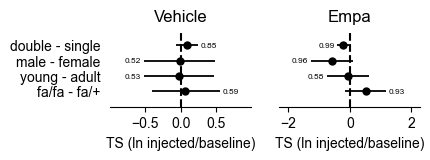

In [19]:
f, axes = plot_effects(overall_ts_vehicle, overall_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_power_change_overall.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

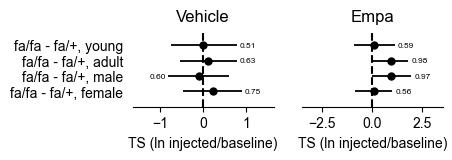

In [24]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_power_change_gtyp_given_sex_age.pdf", bbox_inches="tight", dpi=200)

### Effect of sex given gtyp and given age

In [25]:
sex_ts_vehicle, sex_ts_empa = (get_sex_given_gtyp_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

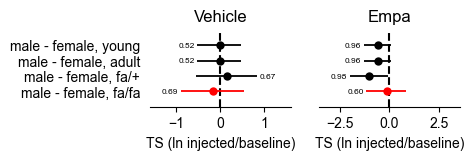

In [28]:
f, axes = plot_effects(sex_ts_vehicle, sex_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_power_change_sex_given_sex_age.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [29]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (overall_ts_vehicle, overall_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
            (sex_ts_vehicle, sex_ts_empa)
        )
    ],
    keys=("overall", "gtyp given sex/age", "sex given age/gtyp"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif     empa  \
contrast           group                                                   
overall            fa/fa - fa/+          0.59100                 0.93425   
                   young - adult         0.47175                 0.41950   
                   male - female         0.48375                 0.04325   
                   double - single       0.85225                 0.00850   
gtyp given sex/age fa/fa - fa/+, female  0.74600                 0.56450   
                   fa/fa - fa/+, male    0.40175                 0.97400   
                   fa/fa - fa/+, adult   0.63450                 0.97875   
                   fa/fa - fa/+, young   0.50675                 0.58675   
sex given age/gtyp male - female, fa/fa  0.31275                 0.39575   
                   male - female, fa/+   0.66850                 0.01950   
                   male - female, adult  0.48375                 0.04325   
                   male - female, young  0.48375                 0.04325   

                                        empa_signif  
contrast           group                             
overall            fa/fa - fa/+                      
                   young - adult                     
                   male - female                     
                   double - single                *  
gtyp given sex/age fa/fa - fa/+, female              
                   fa/fa - fa/+, male                
                   fa/fa - fa/+, adult            *  
                   fa/fa - fa/+, young               
sex given age/gtyp male - female, fa/fa              
                   male - female, fa/+            *  
                   male - female, adult              
                   male - female, young